# 21 · Final Results of the Shift-Aware Detector (v2)

**The question:** Does detector v2 (Notebook 20), built with the new traffic's measurements but without its labels, detect attacks on the official test
file better than v1? And do **weighted** conformal prediction sets restore the promised coverage under the shift?

| | |
|---|---|
| **Input** | Detector v1 (Notebooks 15-17), detector v2 (Notebook 20), the official test file with labels |
| **What we do** | Evaluate v2 once on the test file; compare with v1; test weighted conformal sets; check how well the label-free selection of Notebook 20 worked |
| **Output** | The final, honest comparison of v1 and v2 for the paper |

**Disclosure:** this is the **second** look at the test labels. Notebook 19 (v1) was the pre-registered evaluation. v2 was designed after seeing v1's
result, but **without test labels**. Both results are reported. Nothing in this notebook is changed after looking at the test labels.

## 1. Setup

In [1]:
import sys
import warnings
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())))
warnings.filterwarnings('ignore')

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.optimize import minimize_scalar
from scipy.stats import spearmanr
from sklearn.metrics import confusion_matrix, f1_score, precision_recall_fscore_support

from src.notebook_helpers import TRAIN_CSV, TEST_CSV, RAW_SHA256, CLASSES, DATA, MODELS, TABLES, sha256, save_table, save_figure, save_json, read_json, setup_style
from src.final_detector import FinalDetector, load_raw, apply_temperature, prediction_sets
from src.flow_networks import score
setup_style()
assert sha256(TRAIN_CSV) == RAW_SHA256['train'] and sha256(TEST_CSV) == RAW_SHA256['test']

v1, v2 = FinalDetector.load('v1'), FinalDetector.load('v2')
spec2 = read_json(MODELS / 'final_detector_v2.json')
print('v1:', v1.name, '| v2:', v2.name)
weights = np.load(DATA / '20_importance_weights.npz')
cal_raw = load_raw('calibration')
y_cal = pd.Categorical(cal_raw.attack_cat, categories=CLASSES).codes.astype(int)

v1: LightGBM (sqrt) | v2: LightGBM v2 (all columns + importance weights)


## 2. Calibrate v2 before looking at the test labels

As in Notebook 17, a temperature is fitted on the **calibration rows only**, but now each row counts with its importance weight, so the calibration targets
traffic that looks like the new file. This happens **before** the test labels are loaded.

In [2]:
p_cal2_raw = v2.predict_proba(cal_raw, calibrated=False)
w_cal = weights['calibration']


def weighted_nll(t):
    p = apply_temperature(p_cal2_raw, t)
    return float(-(w_cal * np.log(np.clip(p[np.arange(len(y_cal)), y_cal], 1e-12, 1))).sum() / w_cal.sum())


T2 = float(minimize_scalar(weighted_nll, bounds=(0.05, 20), method='bounded').x)
v2.temperature = T2
p_cal2 = apply_temperature(p_cal2_raw, T2)
print(f'v2 temperature (weighted, calibration rows only): {T2:.3f}')

v2 temperature (weighted, calibration rows only): 1.159


## 3. Load the test file and score both detectors

In [3]:
test = load_raw('test')
y_test = pd.Categorical(test.attack_cat, categories=CLASSES).codes.astype(int)
p1 = v1.predict_proba(test)
p2 = v2.predict_proba(test)
comparison = pd.DataFrame({'v1 (Notebook 19)': score(y_test, p1), 'v2 (shift-aware)': score(y_test, p2)}).T
comparison = comparison.rename(columns={'Worms correct (of 13)': 'Worms correct (of 44)'})
save_table(comparison, '21_v1_vs_v2', index=True)
display(comparison.round(4))

per_class = pd.DataFrame({f'{v} {m}': vals for v, p in [('v1', p1), ('v2', p2)]
                          for m, vals in zip(['precision', 'recall', 'F1'], precision_recall_fscore_support(y_test, p.argmax(1), labels=range(10), zero_division=0)[:3])},
                         index=CLASSES)
per_class['F1 change'] = per_class['v2 F1'] - per_class['v1 F1']
save_table(per_class, '21_per_class', index=True)
display(per_class.round(3))

,macro F1,accuracy,attack recall,false-positive rate,attack avg precision,Worms correct (of 44)
v1 (Notebook 19),0.5177,0.7276,0.9878,0.3249,0.9868,30.0000
v2 (shift-aware),0.5301,0.7284,0.9818,0.3047,0.9858,26.0000


,v1 precision,v1 recall,v1 F1,v2 precision,v2 recall,v2 F1,F1 change
Analysis,0.0360,0.1110,0.0540,0.0450,0.1210,0.0650,0.0110
Backdoor,0.0470,0.1900,0.0760,0.0400,0.2540,0.0700,-0.0060
DoS,0.3470,0.4250,0.3820,0.3370,0.3210,0.3280,-0.0540
Exploits,0.7250,0.6840,0.7040,0.7320,0.6800,0.7050,0.0020
Fuzzers,0.2730,0.6270,0.3800,0.2660,0.5880,0.3670,-0.0140
Generic,0.9980,0.9710,0.9840,0.9970,0.9710,0.9840,-0.0010
Normal,0.9780,0.6750,0.7990,0.9690,0.6950,0.8100,0.0110
Reconnaissance,0.8960,0.8280,0.8610,0.8900,0.8260,0.8570,-0.0030
Shellcode,0.2770,0.9100,0.4250,0.3350,0.8990,0.4890,0.0640
Worms,0.4110,0.6820,0.5130,0.6670,0.5910,0.6270,0.1140


**What we see:**

- **v2 is better than v1 on the test file:** macro F1 **0.530 vs 0.518**, with fewer false alarms (30.5% vs 32.5%) and the same accuracy (0.728).
- The biggest gains are **Worms** (F1 0.51 → 0.63, mainly higher precision) and **Shellcode** (0.43 → 0.49); Normal and Analysis also improve a little.
- The price is **DoS** (F1 0.38 → 0.33) and slightly lower attack recall (98.8% → 98.2%). v2 finds 26 of the 44 Worms flows instead of 30, but raises far
  fewer false Worms alarms.

## 4. Is the difference real?

Bootstrap over the 82,332 test flows (1,000 resamples), as in earlier notebooks.

In [4]:
rng = np.random.default_rng(0)
boot = rng.integers(0, len(y_test), size=(1000, len(y_test)), dtype=np.int32)
pred1, pred2 = p1.argmax(1), p2.argmax(1)
diffs = [f1_score(y_test[i], pred2[i], average='macro', labels=range(10), zero_division=0)
         - f1_score(y_test[i], pred1[i], average='macro', labels=range(10), zero_division=0) for i in boot]
fp1 = ((y_test == CLASSES.index('Normal')) & (pred1 != CLASSES.index('Normal')))
fp2 = ((y_test == CLASSES.index('Normal')) & (pred2 != CLASSES.index('Normal')))
low, high = np.percentile(diffs, [2.5, 97.5])
print(f"macro F1 v2 - v1: {f1_score(y_test, pred2, average='macro', labels=range(10)) - f1_score(y_test, pred1, average='macro', labels=range(10)):+.4f} "
      f"(95% interval {low:+.4f} to {high:+.4f})")
print(f'false alarms on Normal flows: v1 {fp1.sum():,} -> v2 {fp2.sum():,}')

macro F1 v2 - v1: +0.0123 (95% interval +0.0017 to +0.0226)
false alarms on Normal flows: v1 12,020 -> v2 11,274


## 5. Seen versus new flows, and the confusion matrix of v2

,rows,v1 macro F1,v2 macro F1
test flows,,,
seen in training file,8541,0.4077,0.3816
new,73791,0.5339,0.5542


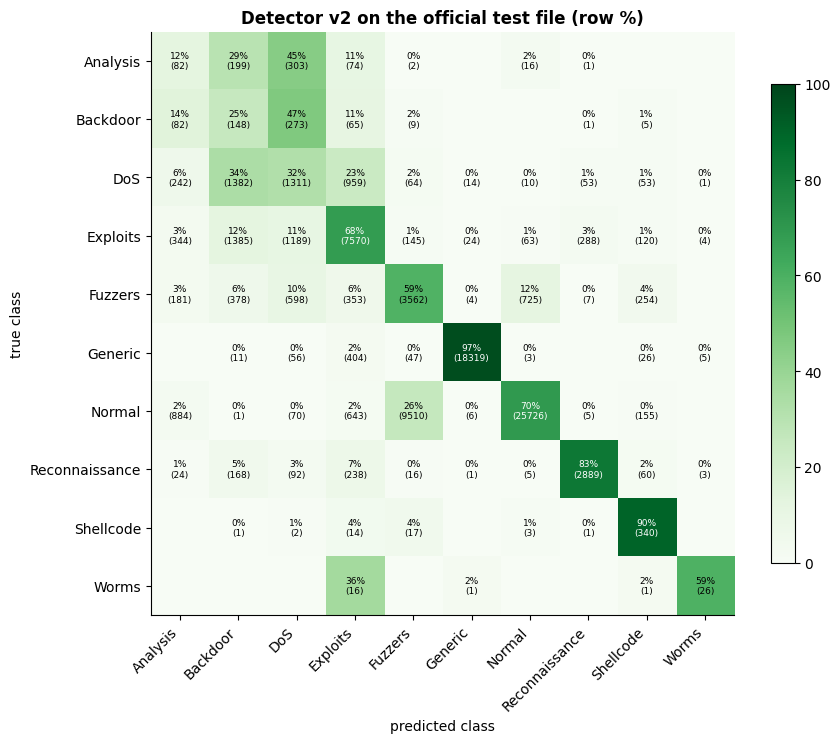

In [5]:
seen = pd.read_csv(DATA / '02_test_overlap_marker.csv').in_training_file.to_numpy()
split = pd.DataFrame([{'test flows': n, 'rows': int(m.sum()), 'v1 macro F1': score(y_test[m], p1[m])['macro F1'],
                       'v2 macro F1': score(y_test[m], p2[m])['macro F1']} for n, m in [('seen in training file', seen), ('new', ~seen)]]).set_index('test flows')
display(split.round(4))

cm = confusion_matrix(y_test, pred2, labels=range(10))
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(cm_pct, cmap='Greens', vmin=0, vmax=100)
ax.set_xticks(range(10), CLASSES, rotation=45, ha='right'); ax.set_yticks(range(10), CLASSES); ax.grid(False)
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            ax.text(j, i, f'{cm_pct[i, j]:.0f}%\n({cm[i, j]})', ha='center', va='center', fontsize=6.5, color='white' if cm_pct[i, j] > 60 else 'black')
ax.set(xlabel='predicted class', ylabel='true class', title='Detector v2 on the official test file (row %)')
fig.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); save_figure(fig, '21_v2_confusion'); plt.show()

**What we see:**

- The gain comes from the **new** test flows (macro F1 0.534 → 0.554); on flows with a twin in the training file v2 is slightly worse (0.408 → 0.382).
  That fits the idea of v2: it gives more weight to training rows that look like the new traffic, and less to the old, repeated patterns.
- The confusion matrix shows the same problem as v1, a little smaller: many Normal flows are still labelled Fuzzers, and DoS, Analysis and Backdoor
  still go mostly to Exploits.

## 6. Weighted conformal prediction sets

Notebook 19 found that ordinary conformal sets lost their 90% coverage on the shifted test file (0.80). **Weighted conformal prediction** fixes the rule
for covariate shift: each calibration row counts with its importance weight, and so does the new flow, when the class threshold is computed.
The weights come from Notebook 20 (no test labels). We compare three versions, all with class-wise thresholds and α = 0.10.

In [6]:
ALPHA = 0.10


def class_sets(p_cal, y_cal, w_cal, p_new, w_new, alpha=ALPHA):
    """Class-wise (Mondrian) conformal sets; with w_cal = w_new = 1 this is the ordinary version of Notebook 17."""
    sets = np.zeros_like(p_new, dtype=bool)
    for k in range(10):
        scores = 1 - p_cal[y_cal == k, k]
        w = w_cal[y_cal == k]
        order = np.argsort(scores)
        scores, cum = scores[order], np.cumsum(w[order])
        target = (1 - alpha) * (cum[-1] + w_new)                    # the new flow's own weight enters the quantile
        idx = np.searchsorted(cum, target)
        q = np.where(idx < len(scores), scores[np.minimum(idx, len(scores) - 1)], np.inf)
        sets[:, k] = (1 - p_new[:, k]) <= q
    empty = ~sets.any(axis=1)
    sets[empty, p_new[empty].argmax(1)] = True
    return sets


ones_cal, ones_test = np.ones(len(y_cal)), np.ones(len(y_test))
versions = {'v1, ordinary sets (Notebook 19)': prediction_sets(p1, v1.calibration['class_thresholds']),   # v1's frozen thresholds from Notebook 17
            'v2, ordinary sets': class_sets(p_cal2, y_cal, ones_cal, p2, ones_test),
            'v2, weighted sets': class_sets(p_cal2, y_cal, w_cal, p2, weights['test'])}
coverage = pd.DataFrame({name: {'coverage (target 0.90)': s[np.arange(len(y_test)), y_test].mean(), 'average set size': s.sum(1).mean(),
                                'single-class sets': (s.sum(1) == 1).mean(),
                                'lowest class coverage': min(s[y_test == k][:, k].mean() for k in range(10))} for name, s in versions.items()}).T
save_table(coverage, '21_conformal', index=True)
display(coverage.round(4))
display(pd.DataFrame({name: [s[y_test == k][:, k].mean() for k in range(10)] for name, s in versions.items()}, index=CLASSES).round(3))

,coverage (target 0.90),average set size,single-class sets,lowest class coverage
"v1, ordinary sets (Notebook 19)",0.8025,1.3755,0.7668,0.6491
"v2, ordinary sets",0.7911,1.3444,0.7734,0.5967
"v2, weighted sets",0.7564,2.0669,0.2475,0.6209


,"v1, ordinary sets (Notebook 19)","v2, ordinary sets","v2, weighted sets"
Analysis,0.8290,0.7180,0.8040
Backdoor,0.9810,0.9470,0.9810
DoS,0.6490,0.5970,0.7310
Exploits,0.8480,0.8040,0.7800
Fuzzers,0.7100,0.7060,0.6210
Generic,0.9660,0.9660,0.6500
Normal,0.7260,0.7230,0.8150
Reconnaissance,0.8800,0.8720,0.8290
Shellcode,0.9310,0.9370,0.9550
Worms,0.9320,0.9550,1.0000


**What we see:**

- **Weighted conformal sets do not restore coverage here:** 0.756, even lower than ordinary sets (0.79-0.80), with much larger sets (2.07 classes on
  average) and far fewer single-class answers (25%).
- They do help exactly where the counters shifted: DoS (0.60 → 0.73), Normal (0.72 → 0.82) and Analysis. But they hurt Generic (0.97 → 0.65) and Fuzzers.
- The method guarantees coverage only if **a measurement pattern keeps the same meaning** in both files. The test file breaks this (Normal flows that look
  like training-file attacks), so no re-weighting of the same calibration rows can fix it. **Honest conclusion:** under this kind of shift, coverage can only
  be restored with some **labelled recent traffic** for re-calibration.

## 7. Did the label-free selection choose well?

Notebook 20 chose among 8 candidates using the importance-weighted (IW) estimate. Now that the test labels are open, we can check **after the fact**
whether that estimate ranked the candidates correctly, compared with the ordinary `model_selection` score. Nothing is re-chosen here.

In [7]:
candidates = pd.read_csv(TABLES / '20_candidates.csv').set_index('candidate')
test_scores, test_fpr = {}, {}
tree_test = v1.pre.transform(test)['tree']
normal = CLASSES.index('Normal')
for name in candidates.index:
    model, keep, dropped = joblib.load(MODELS / f"20_candidate_{name.replace(' ', '_').replace('+', 'plus')}.joblib")
    pred = model.predict(tree_test[:, keep])
    test_scores[name] = f1_score(y_test, pred, average='macro', labels=range(10), zero_division=0)
    test_fpr[name] = ((pred != normal) & (y_test == normal)).sum() / (y_test == normal).sum()
candidates['test macro F1 (after the fact)'] = pd.Series(test_scores)
candidates['test false-positive rate (after the fact)'] = pd.Series(test_fpr)
save_table(candidates, '21_candidates_on_test', index=True)
display(candidates[['macro F1 (model_selection)', 'IW macro F1 (estimate for new traffic)', 'test macro F1 (after the fact)',
                    'test false-positive rate (after the fact)']].round(4))
rho_iw = spearmanr(candidates['IW macro F1 (estimate for new traffic)'], candidates['test macro F1 (after the fact)']).statistic
rho_ms = spearmanr(candidates['macro F1 (model_selection)'], candidates['test macro F1 (after the fact)']).statistic
print(f'rank agreement with the real test ranking: IW estimate {rho_iw:.2f} | ordinary model_selection score {rho_ms:.2f}')
best_on_test = candidates['test macro F1 (after the fact)'].idxmax()
print(f'best candidate on test: {best_on_test}; chosen by the IW estimate: {candidates["IW macro F1 (estimate for new traffic)"].idxmax()}')

,macro F1 (model_selection),IW macro F1 (estimate for new traffic),test macro F1 (after the fact),test false-positive rate (after the fact)
candidate,,,,
all columns,0.6662,0.7043,0.5177,0.3249
all columns + importance weights,0.6596,0.7050,0.5209,0.3168
without TTL,0.6503,0.6929,0.5088,0.3264
without TTL + importance weights,0.6503,0.6925,0.5058,0.3221
without counters,0.6107,0.6408,0.5169,0.3255
without counters + importance weights,0.5842,0.6185,0.4971,0.3277
without TTL and counters,0.6021,0.6347,0.5068,0.3332
without TTL and counters + importance weights,0.5818,0.6113,0.4942,0.3283


rank agreement with the real test ranking: IW estimate 0.88 | ordinary model_selection score 0.86
best candidate on test: all columns + importance weights; chosen by the IW estimate: all columns + importance weights


**What we see:**

- **The label-free selection chose well.** Its choice ("all columns + importance weights") is also the best of the 8 candidates on the test file, and its
  ranking agrees with the true test ranking (Spearman **0.88**, slightly better than the ordinary `model_selection` score, 0.86).
- **Removing the TTL columns does not help** on the test file: macro F1 0.509 instead of 0.518, and false alarms stay at about 32.6%. TTL marks the shifted
  Normal flows, but those flows also look like attacks in other measurements, while TTL is very useful for recognising real attacks.
- Removing the counters does not help either (0.517). Every candidate stays between 0.49 and 0.52 before tuning; the tuned v2 reaches 0.530.

## 8. Save

In [8]:
save_json({'v1': comparison.loc['v1 (Notebook 19)'].to_dict(), 'v2': comparison.loc['v2 (shift-aware)'].to_dict(), 'v2_temperature': T2,
           'coverage': coverage['coverage (target 0.90)'].to_dict(), 'iw_rank_agreement': float(rho_iw), 'ms_rank_agreement': float(rho_ms),
           'disclosure': 'second use of the test labels; v2 designed after v1 test result, without test labels'}, MODELS / '21_final_results_v2.json')
save_json({'temperature': T2, 'alpha': ALPHA, 'note': 'weighted class-wise conformal; thresholds depend on each new flow weight (Notebook 21)'},
          MODELS / '21_calibration_v2.json')
assert sha256(TEST_CSV) == RAW_SHA256['test']
print('Saved.')

Saved.


## Summary

### Final comparison on the official test file

| | v1 (pre-registered, Notebook 19) | v2 (shift-aware, Notebook 20) |
|---|---|---|
| Macro F1 | 0.518 | **0.530** (+0.012, clearly better) |
| Accuracy | 0.728 | 0.728 |
| Attack recall | **98.8%** | 98.2% |
| False-positive rate | 32.5% | **30.5%** |
| Worms | 30 of 44 found | 26 of 44 found, far fewer false Worms alarms |
| Conformal coverage (target 0.90) | 0.80 | 0.79 ordinary / 0.76 weighted |

### What we learned

- **Using the new traffic's measurements (without labels) helps a little and reliably:** +0.012 macro F1, fewer false alarms.
- **The label-free selection works for ranking:** it picked the candidate that is best on the test file.
- **Removing "suspicious" columns (TTL, counters) does not help;** they carry real attack information.
- **The remaining errors come from a change in meaning, not just in frequency:** some Normal test flows look like training-file attacks. Methods that only
  re-weight (importance weights, weighted conformal) cannot fix that; labelled recent traffic would be needed.

### Recommendation

Use **detector v2** for the application, report **both** v1 (pre-registered) and v2 (post-hoc, no test labels) in the paper, and state the remaining
false-alarm rate (about 30% on the shifted test file) honestly, together with the advice to re-calibrate on labelled recent traffic before deployment.